<a href="https://colab.research.google.com/github/bhanukaT56/setExercises/blob/samudhitha-exercise02/Exercise_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Exercise 2: Convolutional Neural Network Classifier



##  Setup and Data Loading


In [1]:
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np, random


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=base_tf)
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

train_loader = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2)
val_loader   = DataLoader(Subset(full_train, val_idx),   batch_size=128, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=128, num_workers=2)


def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        print(f"Epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return h

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def plot_history(h, title):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h["train_loss"], label="train"); ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title}: loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["train_acc"], label="train"); ax[1].plot(epochs, h["val_acc"], label="validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.show()


print("Train / val / test sizes:", len(train_idx), len(val_idx), len(test_set))

Device: cuda


100%|██████████| 170M/170M [11:05<00:00, 256kB/s]


Train / val / test sizes: 45000 5000 10000




**Aim:** replace the MLP of Exercise 1 with a CNN (three trainable layers) on CIFAR-10 and compare the two
using accuracy, training/validation loss and parameter counts.

**Reproduce:** `pip install torch torchvision matplotlib numpy` then *Run All*. CIFAR-10 downloads automatically to `./data`.
A GPU is optional (20 epochs takes a few minutes on CPU for these small models).

**Design notes**
- Same data split, optimiser (Adam, lr 1e-3), batch size (128), epochs (20), loss and seed for both models, so the only change is the architecture.
- The test set is evaluated **once per model, after training**. It is never used for tuning or model selection.

In [1]:
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np, random, json, os

SEED = 42
def set_seed(seed=SEED):
    """Reseed everything so each model gets identical shuffling and a reproducible init."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
os.makedirs("figures", exist_ok=True)
CLASSES = ["aeroplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

Device: cuda


## 1. Data preparation
Standard CIFAR-10 partitions: 50,000 train (split 45,000 train / 5,000 validation) and 10,000 test. Images are converted to tensors and normalised per channel using the training-set mean and standard deviation.

In [2]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

full_train = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=base_tf)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

def make_loaders(seed=SEED):
    """Fresh loaders with a seeded shuffle generator so every model sees the same batch order."""
    g = torch.Generator().manual_seed(seed)
    tr = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2,
                    pin_memory=True, generator=g)
    va = DataLoader(Subset(full_train, val_idx), batch_size=128, num_workers=2, pin_memory=True)
    te = DataLoader(test_set, batch_size=128, num_workers=2, pin_memory=True)
    return tr, va, te

print("Train / val / test sizes:", len(train_idx), len(val_idx), len(test_set))

100%|██████████| 170M/170M [01:08<00:00, 2.48MB/s]


Train / val / test sizes: 45000 5000 10000


## 2. Training and evaluation utilities

In [3]:
def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over `loader`. Trains if an optimiser is given, otherwise evaluates (no gradients)."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        print(f"Epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return h

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def plot_history(h, title, fname=None):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h["train_loss"], label="train"); ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title}: loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["train_acc"], label="train"); ax[1].plot(epochs, h["val_acc"], label="validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=150)
    plt.show()

def final_metrics(model, train_loader, val_loader, test_loader):
    """Eval-mode loss/accuracy on train, val and test (run once, after training)."""
    crit = nn.CrossEntropyLoss()
    res = {}
    for name, ld in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
        res[name + "_loss"], res[name + "_acc"] = run_epoch(model, ld, crit)
    return res

## 3. Models

**MLP (Exercise 1, loaded from the group's saved run)** – three trainable layers: `3072 → 512 → 256 → 10`, ReLU activations. Images are flattened, so the spatial structure is discarded.

**CNN (Exercise 2)** – three trainable layers: two convolutional layers and one fully connected layer.

| Layer | Operation | Output shape |
|---|---|---|
| Conv1 | 3→32, 3×3, pad 1, ReLU, MaxPool 2×2 | 32×16×16 |
| Conv2 | 32→64, 3×3, pad 1, ReLU, MaxPool 2×2 | 64×8×8 |
| FC | flatten (4096) → 10 | 10 |

Pooling and ReLU have no trainable parameters, so the trainable-layer count is three, as required. The output layer returns raw logits because `CrossEntropyLoss` applies softmax internally.

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 10),
        )
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32x16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 64x8x8
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 10))
    def forward(self, x): return self.classifier(self.features(x))

# Sanity check: output shapes and parameter counts
for M in (MLP, CNN):
    m = M(); print(M.__name__, "output:", tuple(m(torch.zeros(2, 3, 32, 32)).shape), "| params:", f"{count_params(m):,}")

MLP output: (2, 10) | params: 1,707,274
CNN output: (2, 10) | params: 60,362


## 4. Train the CNN under the same settings as Exercise 1
Adam, lr = 1e-3, batch size 128, 20 epochs, seed 42, cross-entropy loss. The MLP is **not retrained**: place `exercise1_mlp_results.json` and `exercise1_mlp.pt` (saved by the Exercise 1 notebook) next to this notebook and they are loaded. If they are missing, the MLP is retrained with the same settings.

Exercise 1 files not found - retraining the MLP with identical settings.

===== MLP =====
Epoch  1 | train loss 1.658 acc 0.413 | val loss 1.538 acc 0.457
Epoch  2 | train loss 1.451 acc 0.488 | val loss 1.475 acc 0.494
Epoch  3 | train loss 1.341 acc 0.525 | val loss 1.414 acc 0.500
Epoch  4 | train loss 1.251 acc 0.558 | val loss 1.415 acc 0.506
Epoch  5 | train loss 1.167 acc 0.587 | val loss 1.413 acc 0.515
Epoch  6 | train loss 1.090 acc 0.613 | val loss 1.439 acc 0.521
Epoch  7 | train loss 1.010 acc 0.643 | val loss 1.491 acc 0.512
Epoch  8 | train loss 0.944 acc 0.665 | val loss 1.483 acc 0.520
Epoch  9 | train loss 0.869 acc 0.693 | val loss 1.516 acc 0.526
Epoch 10 | train loss 0.801 acc 0.715 | val loss 1.576 acc 0.525
Epoch 11 | train loss 0.743 acc 0.736 | val loss 1.638 acc 0.518
Epoch 12 | train loss 0.683 acc 0.757 | val loss 1.711 acc 0.524
Epoch 13 | train loss 0.624 acc 0.778 | val loss 1.842 acc 0.513
Epoch 14 | train loss 0.590 acc 0.791 | val loss 1.883 acc 0.503


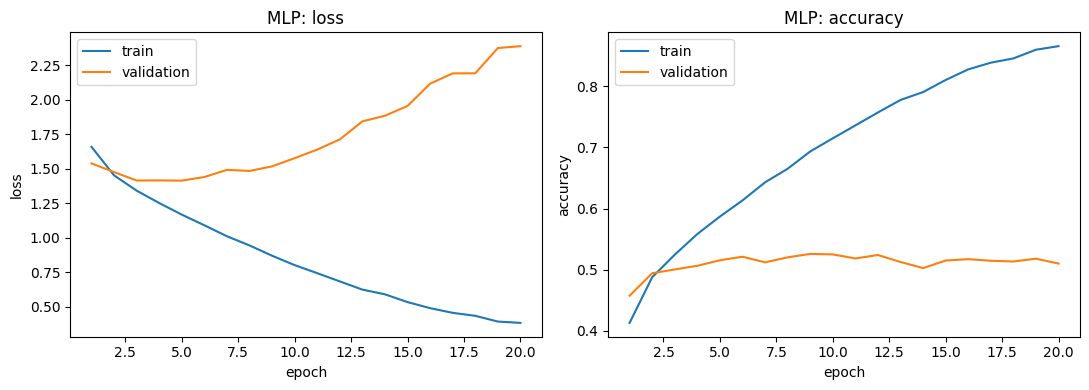


===== CNN =====
Epoch  1 | train loss 1.392 acc 0.509 | val loss 1.152 acc 0.600
Epoch  2 | train loss 1.041 acc 0.639 | val loss 0.986 acc 0.668
Epoch  3 | train loss 0.905 acc 0.688 | val loss 0.929 acc 0.682
Epoch  4 | train loss 0.819 acc 0.717 | val loss 0.895 acc 0.694
Epoch  5 | train loss 0.752 acc 0.742 | val loss 0.886 acc 0.696
Epoch  6 | train loss 0.696 acc 0.762 | val loss 0.860 acc 0.703
Epoch  7 | train loss 0.651 acc 0.775 | val loss 0.882 acc 0.699
Epoch  8 | train loss 0.610 acc 0.792 | val loss 0.861 acc 0.708
Epoch  9 | train loss 0.569 acc 0.805 | val loss 0.840 acc 0.719
Epoch 10 | train loss 0.530 acc 0.818 | val loss 0.868 acc 0.718
Epoch 11 | train loss 0.507 acc 0.825 | val loss 0.869 acc 0.715
Epoch 12 | train loss 0.475 acc 0.836 | val loss 0.872 acc 0.721
Epoch 13 | train loss 0.447 acc 0.846 | val loss 0.918 acc 0.709
Epoch 14 | train loss 0.425 acc 0.853 | val loss 0.931 acc 0.720
Epoch 15 | train loss 0.396 acc 0.863 | val loss 0.990 acc 0.704
Epoch 16

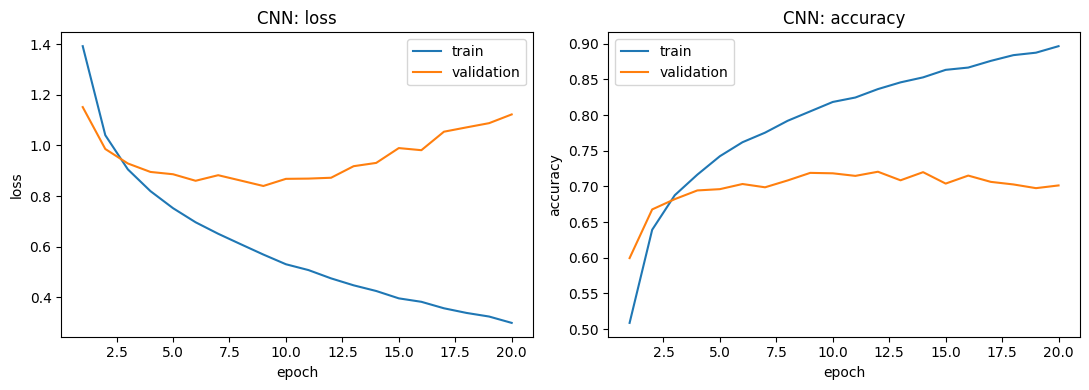

In [5]:
EPOCHS, LR = 20, 1e-3          # identical to Exercise 1
results, histories, models = {}, {}, {}

def train_and_eval(name, M):
    print(f"\n===== {name} =====")
    set_seed()                                   # reproducible init and shuffle order
    tr, va, te = make_loaders()
    model = M()
    histories[name] = fit(model, tr, va, epochs=EPOCHS, lr=LR)
    models[name] = model
    plot_history(histories[name], name, fname=f"ex2_{name.lower()}_curves")
    results[name] = final_metrics(model, tr, va, te)   # test set touched only here
    results[name]["params"] = count_params(model)

# --- MLP: reuse the group's Exercise 1 run so both report sections quote the same numbers ---
if os.path.exists("exercise1_mlp_results.json") and os.path.exists("exercise1_mlp.pt"):
    with open("exercise1_mlp_results.json") as f: r1 = json.load(f)
    histories["MLP"] = r1.pop("history"); r1.pop("model", None)
    results["MLP"] = r1
    mlp = MLP(); mlp.load_state_dict(torch.load("exercise1_mlp.pt", map_location=device)); mlp.to(device).eval()
    assert count_params(mlp) == results["MLP"]["params"], "Saved MLP does not match the MLP class above"
    models["MLP"] = mlp
    print("Loaded Exercise 1 MLP results and weights.")
    plot_history(histories["MLP"], "MLP (Exercise 1)", fname="ex2_mlp_curves")
else:
    print("Exercise 1 files not found - retraining the MLP with identical settings.")
    train_and_eval("MLP", MLP)

train_and_eval("CNN", CNN)

## 5. Comparison: MLP vs CNN

In [6]:
hdr = f"{'Model':<6}{'Params':>12}{'Train acc':>11}{'Val acc':>9}{'Test acc':>10}{'Train loss':>12}{'Val loss':>10}{'Test loss':>11}{'Gap (tr-te)':>13}"
print(hdr); print("-" * len(hdr))
for n, r in results.items():
    print(f"{n:<6}{r['params']:>12,}{r['train_acc']:>11.3f}{r['val_acc']:>9.3f}{r['test_acc']:>10.3f}"
          f"{r['train_loss']:>12.3f}{r['val_loss']:>10.3f}{r['test_loss']:>11.3f}{r['train_acc']-r['test_acc']:>13.3f}")
print(f"\nCNN uses {results['MLP']['params']/results['CNN']['params']:.1f}x fewer parameters than the MLP.")

with open("ex2_results.json", "w") as f: json.dump({"results": results, "histories": histories}, f, indent=2)

Model       Params  Train acc  Val acc  Test acc  Train loss  Val loss  Test loss  Gap (tr-te)
----------------------------------------------------------------------------------------------
MLP      1,707,274      0.888    0.510     0.519       0.325     2.386      2.415        0.368
CNN         60,362      0.915    0.701     0.696       0.256     1.123      1.159        0.219

CNN uses 28.3x fewer parameters than the MLP.


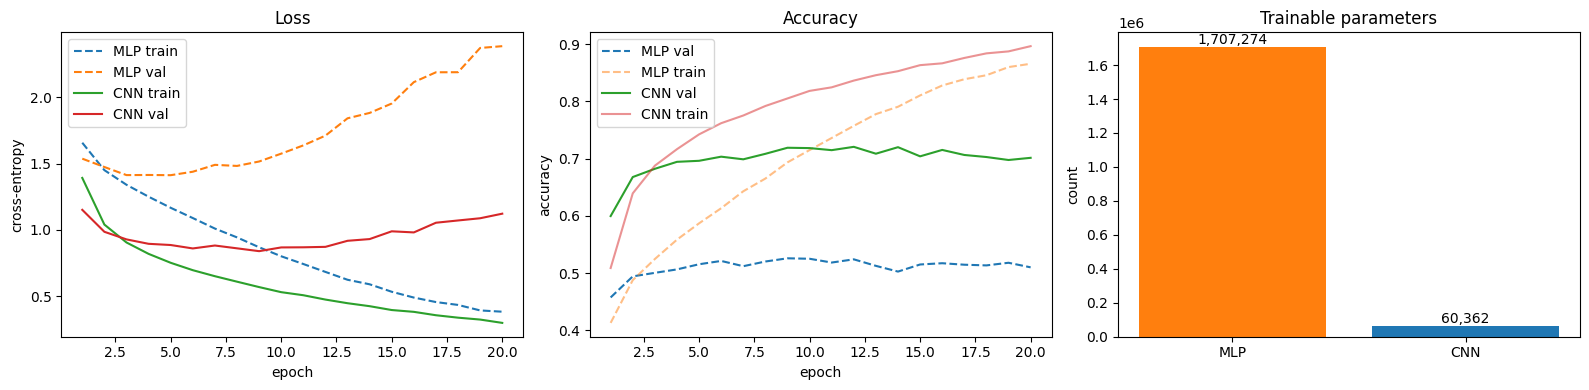

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ep = range(1, EPOCHS + 1)
for n, ls in [("MLP", "--"), ("CNN", "-")]:
    h = histories[n]
    ax[0].plot(ep, h["train_loss"], ls, label=f"{n} train"); ax[0].plot(ep, h["val_loss"], ls, label=f"{n} val")
    ax[1].plot(ep, h["val_acc"], ls, label=f"{n} val")
    ax[1].plot(ep, h["train_acc"], ls, alpha=0.5, label=f"{n} train")
ax[0].set(title="Loss", xlabel="epoch", ylabel="cross-entropy"); ax[0].legend()
ax[1].set(title="Accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
names = list(results)
ax[2].bar(names, [results[n]["params"] for n in names], color=["tab:orange", "tab:blue"])
ax[2].set(title="Trainable parameters", ylabel="count")
for i, n in enumerate(names): ax[2].text(i, results[n]["params"], f"{results[n]['params']:,}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig("figures/ex2_mlp_vs_cnn.png", dpi=150); plt.show()

### Per-class test accuracy



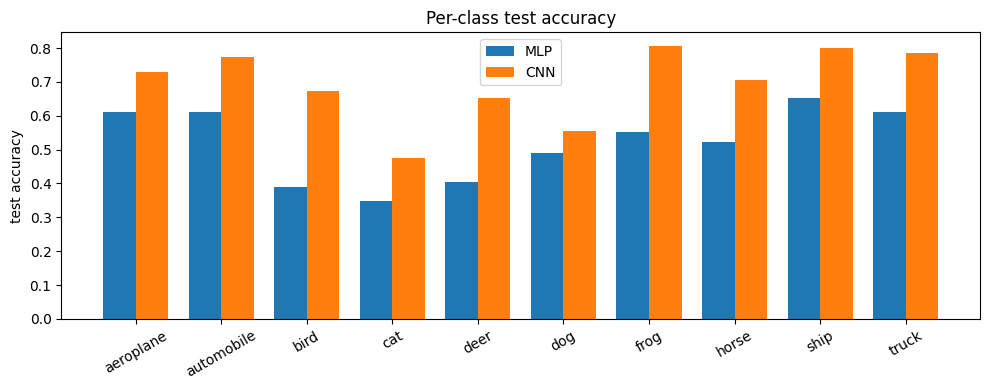

In [8]:
@torch.no_grad()
def per_class_acc(model, loader):
    model.eval(); correct = torch.zeros(10); total = torch.zeros(10)
    for x, y in loader:
        pred = model(x.to(device)).argmax(1).cpu()
        for c in range(10):
            m = y == c; total[c] += m.sum(); correct[c] += (pred[m] == c).sum()
    return (correct / total).numpy()

_, _, te = make_loaders()
pc = {n: per_class_acc(models[n], te) for n in models}
x = np.arange(10); w = 0.38
plt.figure(figsize=(10, 4))
plt.bar(x - w/2, pc["MLP"], w, label="MLP"); plt.bar(x + w/2, pc["CNN"], w, label="CNN")
plt.xticks(x, CLASSES, rotation=30); plt.ylabel("test accuracy"); plt.title("Per-class test accuracy"); plt.legend()
plt.tight_layout(); plt.savefig("figures/ex2_per_class.png", dpi=150); plt.show()

### What did the first convolutional layer learn?
The 32 first-layer kernels (3×3×3) are shown as small RGB images. Typical results are oriented edge and colour-blob detectors, which a flattened MLP has no way to share across positions.

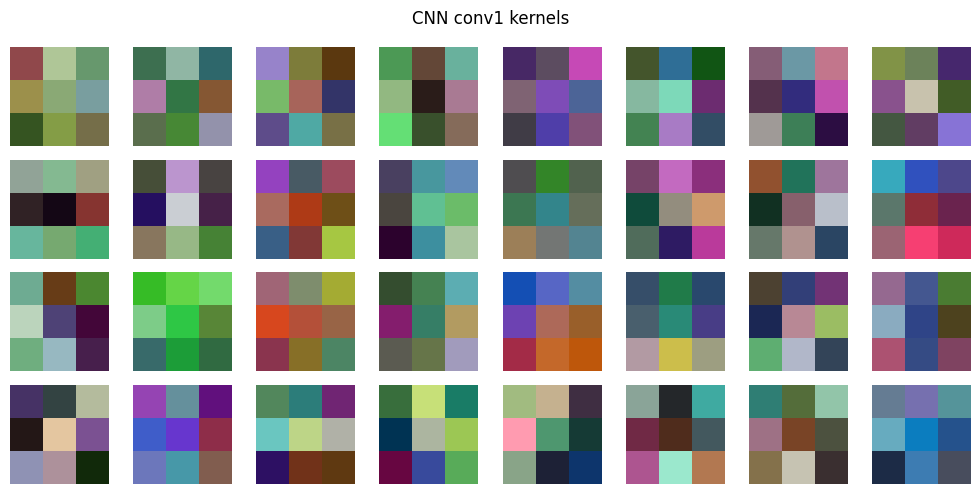

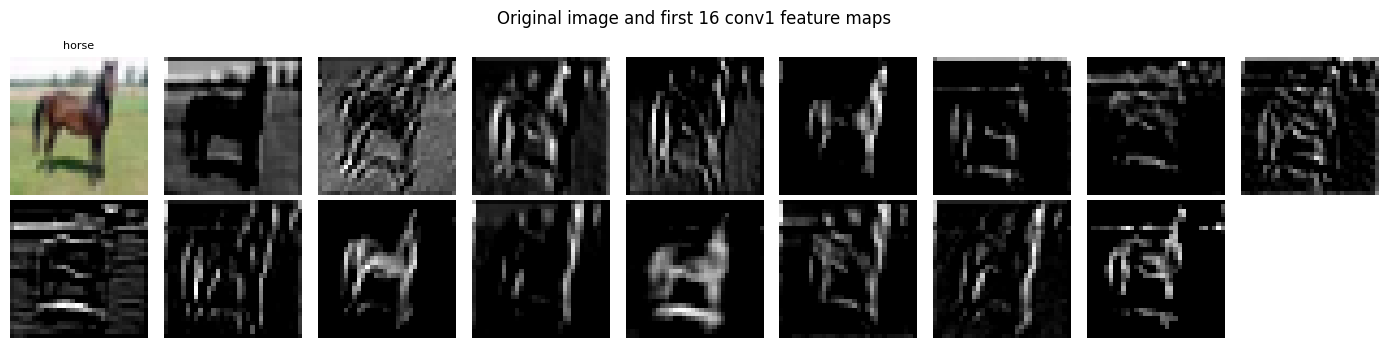

In [9]:
w = models["CNN"].features[0].weight.detach().cpu()           # (32, 3, 3, 3)
w = (w - w.min()) / (w.max() - w.min())                       # rescale to [0, 1] for display
fig, axs = plt.subplots(4, 8, figsize=(10, 5))
for i, a in enumerate(axs.flat): a.imshow(w[i].permute(1, 2, 0)); a.axis("off")
plt.suptitle("CNN conv1 kernels"); plt.tight_layout(); plt.savefig("figures/ex2_conv1_kernels.png", dpi=150); plt.show()

# Feature maps for one validation image
img, label = full_train[val_idx[0]]
with torch.no_grad(): fm = torch.relu(models["CNN"].features[0](img.unsqueeze(0).to(device))).cpu()[0]
fig, axs = plt.subplots(2, 9, figsize=(14, 3.5))
orig = (img * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)
axs[0, 0].imshow(orig.permute(1, 2, 0)); axs[0, 0].set_title(CLASSES[label], fontsize=8)
for a in axs.flat: a.axis("off")
for i, a in enumerate(list(axs.flat)[1:17]): a.imshow(fm[i], cmap="gray")
plt.suptitle("Original image and first 16 conv1 feature maps"); plt.tight_layout(); plt.show()

## 6. Discussion

> **Fill in after running** with your actual numbers. Do not copy figures from another run: the code and report must be consistent. Points to cover (marking scheme rewards critical interpretation):

**Accuracy.** Report test accuracy for both models and the train-test gap. State which model generalises better and by how much.

**Loss curves.** Does the MLP's validation loss turn upward while training loss keeps falling (overfitting)? Compare with the CNN's curves: where does the validation loss bottom out, and does the CNN also begin to overfit late in training?

**Parameters.** The CNN has about 60k trainable parameters against the MLP's 1.7M. Link this to accuracy: more parameters did not mean better performance, so *how* parameters are used matters more than how many there are.

**Why convolutions help on images.**
- *Local connectivity:* each unit looks at a small 3×3 neighbourhood, matching the fact that nearby pixels are strongly correlated.
- *Weight sharing / translation equivariance:* one kernel is applied at every position, so an edge detector learned once works everywhere. An MLP must relearn the same feature at each location.
- *Hierarchical features:* conv1 learns edges and colour blobs (see the kernel plot), conv2 combines them into textures and parts.
- *Pooling:* gives some tolerance to small shifts and reduces the size of the classifier input.
- The MLP flattens the image, discarding 2-D structure, and needs far more weights to compensate.

**Limitations.** Single run with one seed, so small differences may be within run-to-run variation; the CNN is deliberately shallow; final-epoch weights are reported rather than the best-validation epoch.